### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [66]:
data = pd.read_csv('data/coupons.csv')

In [67]:
data.head()


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [68]:
data.info()

# Get the total number rows and columns in the dataset
num_origin_rows, num_origin_cols = data.shape
print(f"Number of rows: {num_origin_rows}, Number of columns: {num_origin_cols}")



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12684 non-null  object
 1   passanger             12684 non-null  object
 2   weather               12684 non-null  object
 3   temperature           12684 non-null  int64 
 4   time                  12684 non-null  object
 5   coupon                12684 non-null  object
 6   expiration            12684 non-null  object
 7   gender                12684 non-null  object
 8   age                   12684 non-null  object
 9   maritalStatus         12684 non-null  object
 10  has_children          12684 non-null  int64 
 11  education             12684 non-null  object
 12  occupation            12684 non-null  object
 13  income                12684 non-null  object
 14  car                   108 non-null    object
 15  Bar                   12577 non-null

In [69]:
data.describe(include="all")

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
count,12684,12684,12684,12684.000000,12684,12684,12684,12684,12684,12684,...,12467,12533,12554,12495,12684.0,12684.000000,12684.000000,12684.000000,12684.000000,12684.000000
unique,3,4,3,NaN,5,5,2,2,8,5,...,5,5,5,5,NaN,NaN,NaN,NaN,NaN,NaN
top,No Urgent Place,Alone,Sunny,NaN,6PM,Coffee House,1d,Female,21,Married partner,...,less1,1~3,1~3,less1,NaN,NaN,NaN,NaN,NaN,NaN
freq,6283,7305,10069,NaN,3230,3996,7091,6511,2653,5100,...,3385,4672,5376,6077,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,63.301798,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.0,0.561495,0.119126,0.214759,0.785241,0.568433
std,NaN,NaN,NaN,19.154486,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.0,0.496224,0.323950,0.410671,0.410671,0.495314
min,NaN,NaN,NaN,30.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.0,0.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.0,0.000000,0.000000,0.000000,1.000000,0.000000
50%,NaN,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.0,1.000000,0.000000,0.000000,1.000000,1.000000
75%,NaN,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.0,1.000000,0.000000,0.000000,1.000000,1.000000


In [70]:
# Check duplicate rows and inspect the categorical values for inconsistencies.
print(f"Duplicate rows: {data.duplicated().sum()}\n")
# Check for categorical columns and their unique values drop the NaN values and sort the unique values for better readability.
for column in data.select_dtypes(include='object'):
    print(f"{column}: {sorted(data[column].dropna().unique())}")


Duplicate rows: 74

destination: ['Home', 'No Urgent Place', 'Work']
passanger: ['Alone', 'Friend(s)', 'Kid(s)', 'Partner']
weather: ['Rainy', 'Snowy', 'Sunny']
time: ['10AM', '10PM', '2PM', '6PM', '7AM']
coupon: ['Bar', 'Carry out & Take away', 'Coffee House', 'Restaurant(20-50)', 'Restaurant(<20)']
expiration: ['1d', '2h']
gender: ['Female', 'Male']
age: ['21', '26', '31', '36', '41', '46', '50plus', 'below21']
maritalStatus: ['Divorced', 'Married partner', 'Single', 'Unmarried partner', 'Widowed']
education: ['Associates degree', 'Bachelors degree', 'Graduate degree (Masters or Doctorate)', 'High School Graduate', 'Some High School', 'Some college - no degree']
occupation: ['Architecture & Engineering', 'Arts Design Entertainment Sports & Media', 'Building & Grounds Cleaning & Maintenance', 'Business & Financial', 'Community & Social Services', 'Computer & Mathematical', 'Construction & Extraction', 'Education&Training&Library', 'Farming Fishing & Forestry', 'Food Preparation & Serv

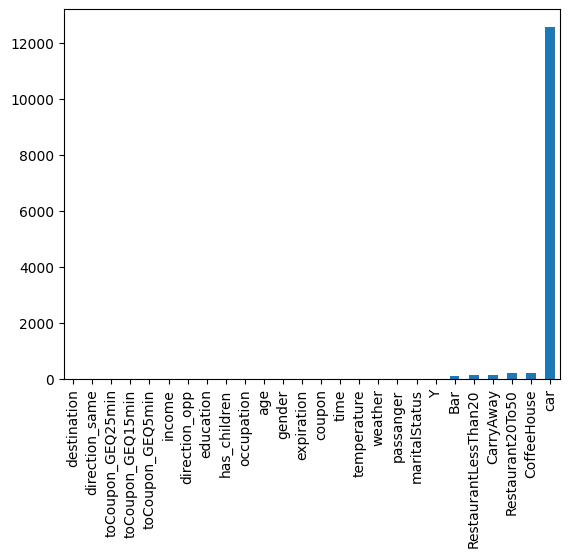

destination              0.000000
passanger                0.000000
weather                  0.000000
temperature              0.000000
time                     0.000000
coupon                   0.000000
expiration               0.000000
gender                   0.000000
age                      0.000000
maritalStatus            0.000000
has_children             0.000000
education                0.000000
occupation               0.000000
income                   0.000000
car                     99.148534
Bar                      0.843582
CoffeeHouse              1.710817
CarryAway                1.190476
RestaurantLessThan20     1.024913
Restaurant20To50         1.490066
toCoupon_GEQ5min         0.000000
toCoupon_GEQ15min        0.000000
toCoupon_GEQ25min        0.000000
direction_same           0.000000
direction_opp            0.000000
Y                        0.000000
dtype: float64


In [71]:
# Plot the number of missing values in each column as a bar chart 
import matplotlib.pyplot as plt
data.isnull().sum().sort_values(ascending=True).plot(kind='bar')
plt.show()

# Display the number of % missing values in each    
missing_values = data.isnull().sum() / len(data) * 100
print (missing_values)


3. Decide what to do about your missing data -- drop, replace, other...

In [72]:
# From above plot car has max missing values. We will fill it as unknown, and later we may drop this column if it is not useful for our analysis.
data['car'] = data['car'].fillna('unknown')

# for other missing values we can drop the rows as they are very less in number and will not impact our analysis much.
data = data.dropna()

data.info()

num_rows, num_cols = data.shape
print(f"Number of rows: {num_rows} (original {num_origin_rows} {(num_rows - num_origin_rows)/num_origin_rows*100:.2f}% change), Number of columns: {num_cols} (original {num_origin_cols} {num_cols - num_origin_cols} change)")

<class 'pandas.core.frame.DataFrame'>
Index: 12079 entries, 22 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12079 non-null  object
 1   passanger             12079 non-null  object
 2   weather               12079 non-null  object
 3   temperature           12079 non-null  int64 
 4   time                  12079 non-null  object
 5   coupon                12079 non-null  object
 6   expiration            12079 non-null  object
 7   gender                12079 non-null  object
 8   age                   12079 non-null  object
 9   maritalStatus         12079 non-null  object
 10  has_children          12079 non-null  int64 
 11  education             12079 non-null  object
 12  occupation            12079 non-null  object
 13  income                12079 non-null  object
 14  car                   12079 non-null  object
 15  Bar                   12079 non-null  ob

4. What proportion of the total observations chose to accept the coupon?



In [73]:
# Find out % of accepted coupons
accepted_percentage = (data['Y'].sum() / len(data)) * 100
print(f"Propertion  of accepted coupons: {accepted_percentage:.2f}%")    


Propertion  of accepted coupons: 56.93%


5. Use a bar plot to visualize the `coupon` column.

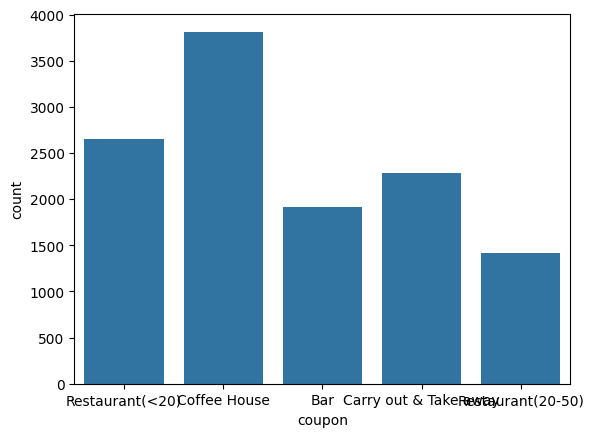

In [74]:
# Plot the copupon column as bar plot using seaborn
sns.countplot(x='coupon', data=data, )
plt.show()

6. Use a histogram to visualize the temperature column.

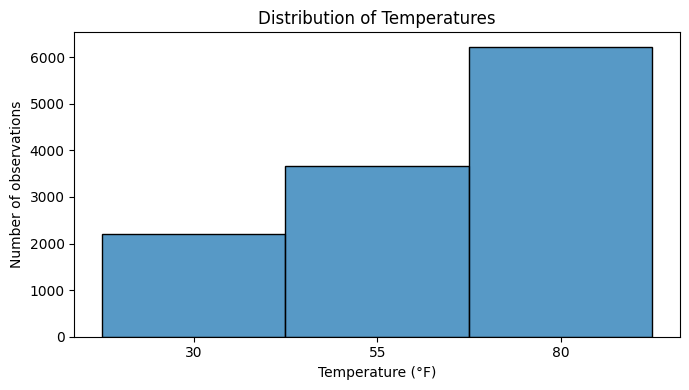

In [75]:
# Temperature is discrete in this survey, so align bins with its three values.
plt.figure(figsize=(7, 4))
# based on the data, we can set the bins to be [17.5, 42.5, 67.5, 92.5] to align with 30 - cold , 55 - mild , 80 - hot). 
sns.histplot(data=data, x='temperature', bins=[17.5, 42.5, 67.5, 92.5])
#sns.histplot(data=data, x='temperature')

plt.xticks([30, 55, 80])
plt.title('Distribution of Temperatures')
plt.xlabel('Temperature (°F)')
plt.ylabel('Number of observations')
plt.tight_layout()
plt.show()


### Data observations

Filled in the mostly empty car column with "unknown" and removed any remaining rows with missing info. That left us with 12,079 responses (95.2% of the original data), where the overall coupon acceptance rate was 56.9%. The comparisons below show trends in the data, but they don't prove that one factor directly causes another.


,observations,acceptance_rate
coupon,,
Carry out & Take away,2280,73.8%
Restaurant(<20),2653,70.9%
Coffee House,3816,49.6%
Restaurant(20-50),1417,44.6%
Bar,1913,41.2%


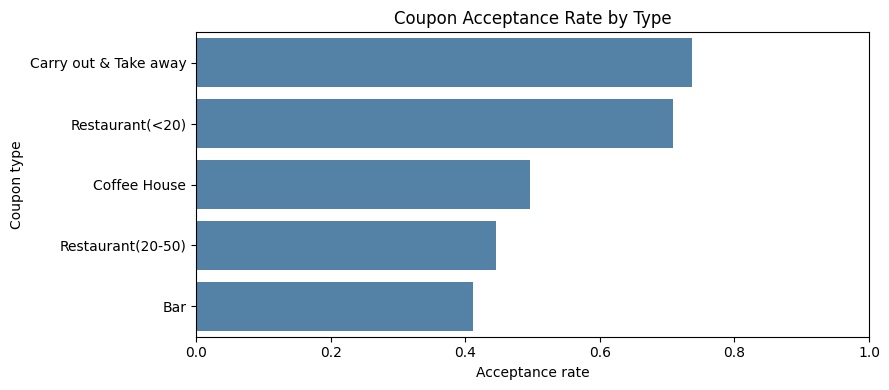

In [111]:
# Improve the coupon chart by showing acceptance rate as well as sample size.
coupon_summary = (data.groupby('coupon')['Y']
                  .agg(observations='size', acceptance_rate='mean')
                  .sort_values('acceptance_rate', ascending=False))
display(coupon_summary.style.format({'acceptance_rate': '{:.1%}'}))

plt.figure(figsize=(9, 4))
sns.barplot(data=coupon_summary.reset_index(), x='acceptance_rate', y='coupon', color='steelblue')
plt.xlim(0, 1)
plt.xlabel('Acceptance rate')
plt.ylabel('Coupon type')
plt.title('Coupon Acceptance Rate by Type')
plt.tight_layout()
plt.show()


Carry-out and inexpensive-restaurant coupons have the highest acceptance rates. Bar coupons have the lowest rate, motivating a closer look at which drivers accept them.


**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [112]:


bar_data = data.loc[data['coupon'].eq('Bar')].copy()
print(f"Bar-coupon observations: {len(bar_data):,}")


Bar-coupon observations: 1,913


2. What proportion of bar coupons were accepted?


In [113]:
bar_acceptance = bar_data['Y'].mean()
print(f"Bar coupon acceptance rate: {bar_acceptance:.1%}")


Bar coupon acceptance rate: 41.2%



3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


,observations,acceptance_rate
bar_frequency_group,,
3 or fewer times/month,1720,37.3%
More than 3 times/month,193,76.2%


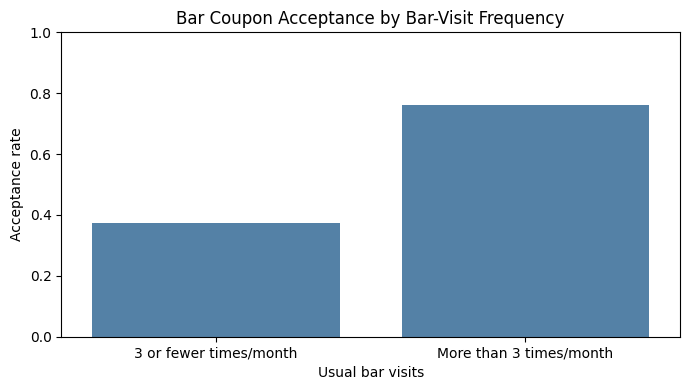

In [114]:
# Map the bar-visit frequency to a numeric value for analysis.
frequency_map = {'never': 0, 'less1': 0.5, '1~3': 2, '4~8': 6, 'gt8': 9}
bar_data['bar_visits'] = bar_data['Bar'].map(frequency_map)


bar_data['bar_frequency_group'] = np.where(
    bar_data['bar_visits'].le(3), '3 or fewer times/month', 'More than 3 times/month'
)
bar_frequency_comparison = (bar_data.groupby('bar_frequency_group')['Y']
                            .agg(observations='size', acceptance_rate='mean'))
display(bar_frequency_comparison.style.format({'acceptance_rate': '{:.1%}'}))

plt.figure(figsize=(7, 4))
sns.barplot(data=bar_frequency_comparison.reset_index(),
            x='bar_frequency_group', y='acceptance_rate', color='steelblue')
plt.ylim(0, 1)
plt.xlabel('Usual bar visits')
plt.ylabel('Acceptance rate')
plt.title('Bar Coupon Acceptance by Bar-Visit Frequency')
plt.tight_layout()
plt.show()


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to all others. Is there a difference?


In [115]:
# Map the age to a numeric value for analysis.
age_map = {'below21': 20, '21': 21, '26': 26, '31': 31,
           '36': 36, '41': 41, '46': 46, '50plus': 51}
bar_data['age_numeric'] = bar_data['age'].map(age_map)


frequent_older = bar_data['bar_visits'].gt(1) & bar_data['age_numeric'].gt(25)
comparison_4 = (bar_data.assign(group=np.where(
                    frequent_older, 'Bar >1/month and age >25', 'All other bar-coupon drivers'))
                .groupby('group')['Y']
                .agg(observations='size', acceptance_rate='mean'))
display(comparison_4.style.format({'acceptance_rate': '{:.1%}'}))
print('The frequent and over-25 group accepted at 69.0%, versus 33.8% for all others.')



,observations,acceptance_rate
group,,
All other bar-coupon drivers,1510,33.8%
Bar >1/month and age >25,403,69.0%


The frequent and over-25 group accepted at 69.0%, versus 33.8% for all others.


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [116]:


frequent_non_kid_non_farming = (
    bar_data['bar_visits'].gt(1)
    & bar_data['passanger'].ne('Kid(s)')
    & bar_data['occupation'].ne('Farming Fishing & Forestry')
)
comparison_5 = (bar_data.assign(group=np.where(
                    frequent_non_kid_non_farming,
                    'Bar >1/month; no kid passenger; non-farming occupation',
                    'All other bar-coupon drivers'))
                .groupby('group')['Y']
                .agg(observations='size', acceptance_rate='mean'))
display(comparison_5.style.format({'acceptance_rate': '{:.1%}'}))
print('The selected group accepted at 70.9%, versus 29.8% for all others.')


,observations,acceptance_rate
group,,
All other bar-coupon drivers,1383,29.8%
Bar >1/month; no kid passenger; non-farming occupation,530,70.9%


The selected group accepted at 70.9%, versus 29.8% for all others.


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [117]:
bar_data['cheap_restaurant_visits'] = bar_data['RestaurantLessThan20'].map(frequency_map)

income_under_50k = bar_data['income'].isin([
    'Less than $12500', '$12500 - $24999', '$25000 - $37499', '$37500 - $49999'
])


condition_a = (bar_data['bar_visits'].gt(1)
               & bar_data['passanger'].ne('Kid(s)')
               & bar_data['maritalStatus'].ne('Widowed'))
condition_b = bar_data['bar_visits'].gt(1) & bar_data['age_numeric'].lt(30)
condition_c = bar_data['cheap_restaurant_visits'].gt(4) & income_under_50k

condition_summary = pd.DataFrame({
    'condition': [
        'Bar >1/month, no kid passenger, not widowed',
        'Bar >1/month and age <30',
        'Cheap restaurant >4/month and income <50K',
        'At least one of the three conditions'
    ],
    'observations': [condition_a.sum(), condition_b.sum(), condition_c.sum(),
                     (condition_a | condition_b | condition_c).sum()],
    'acceptance_rate': [
        bar_data.loc[condition_a, 'Y'].mean(),
        bar_data.loc[condition_b, 'Y'].mean(),
        bar_data.loc[condition_c, 'Y'].mean(),
        bar_data.loc[condition_a | condition_b | condition_c, 'Y'].mean()
    ]
})
display(condition_summary.style.format({'acceptance_rate': '{:.1%}'}))


,condition,observations,acceptance_rate
0,"Bar >1/month, no kid passenger, not widowed",530,70.9%
1,Bar >1/month and age <30,328,72.0%
2,Cheap restaurant >4/month and income <50K,333,45.6%
3,At least one of the three conditions,746,58.7%


7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

- Bar habit is the biggest driver: People who already go to bars regularly are far more likely to accept bar coupons.

- Frequency makes a massive difference:
    - Frequent bar-goers (4+ visits/month): 76.2% accepted
    - Occasional/Non-visitors (3 or fewer visits/month): 37.3% accepted

- Other top-performing groups: Acceptance stays very high (about 69–71%) for bar-goers who are over 25, driving without kids, or working in non-agricultural jobs.

- Takeaway: Prior bar-going behavior is the single strongest indicator of coupon interest. While age and passenger context help refine the picture, but does not conclude on direct effect

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

In [86]:
# Check the acceptance rate for coupons  on other than bar 

coupon_summary = (
    data.groupby('coupon')['Y']
    .agg(
        total_coupons=('count'),
        accepted_count=('sum'),
        acceptance_rate=('mean')
    )
    .assign(acceptance_pct=lambda x: (x['acceptance_rate'] * 100).round(1))
    .sort_values(by='acceptance_pct', ascending=False)
)

display(coupon_summary)

,total_coupons,accepted_count,acceptance_rate,acceptance_pct
coupon,,,,
Carry out & Take away,2280,1682,0.737719,73.8
Restaurant(<20),2653,1881,0.709009,70.9
Coffee House,3816,1894,0.496331,49.6
Restaurant(20-50),1417,632,0.446013,44.6
Bar,1913,788,0.411918,41.2


#### Coffee House coupons

I investigate coffee-house coupons because they are the largest coupon group and have an overall acceptance rate close to 50% with max acceptace by number. Compare acceptance with prior coffee-house visits and with other contextual factors.


In [87]:
coffee_data = data.loc[data['coupon'].eq('Coffee House')].copy()
coffee_data['coffee_visits'] = coffee_data['CoffeeHouse'].map(frequency_map)
coffee_data['age_numeric'] = coffee_data['age'].map(age_map)

print(f"Coffee-house observations: {len(coffee_data):,}")
print(f"Overall coffee-house acceptance rate: {coffee_data['Y'].mean():.1%}")


Coffee-house observations: 3,816
Overall coffee-house acceptance rate: 49.6%


,observations,acceptance_rate
CoffeeHouse,,
never,896,17.5%
less1,1052,48.1%
1~3,1019,64.8%
4~8,507,68.2%
gt8,342,65.8%


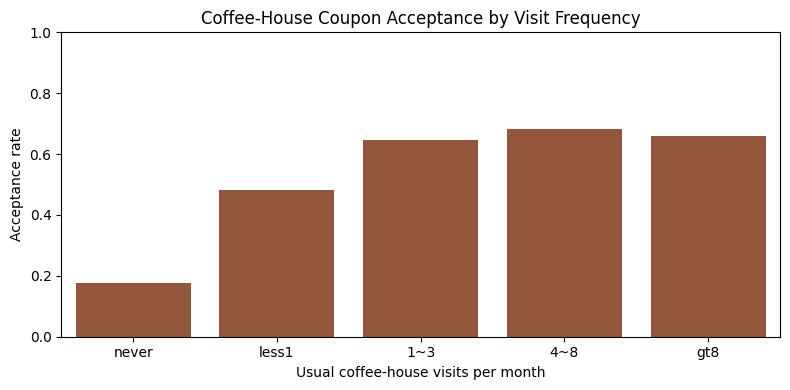

In [88]:
# Existing visit behavior analysis for coffee-house coupon acceptance. This is the clearest customer-level discriminator as lerned from the bar-coupon analysis.
coffee_frequency = (coffee_data.groupby('CoffeeHouse', observed=False)['Y']
                    .agg(observations='size', acceptance_rate='mean')
                    .reindex(['never', 'less1', '1~3', '4~8', 'gt8']))
display(coffee_frequency.style.format({'acceptance_rate': '{:.1%}'}))

plt.figure(figsize=(8, 4))
sns.barplot(data=coffee_frequency.reset_index(), x='CoffeeHouse',
            y='acceptance_rate', color='sienna')
plt.ylim(0, 1)
plt.xlabel('Usual coffee-house visits per month')
plt.ylabel('Acceptance rate')
plt.title('Coffee-House Coupon Acceptance by Visit Frequency')
plt.tight_layout()
plt.show()


,factor,group,observations,acceptance_rate
0,Coffee house >1/month,Condition met,1868,65.9%
1,Coffee house >1/month,Condition not met,1948,34.0%
2,Age under 30,Condition met,1784,52.9%
3,Age under 30,Condition not met,2032,46.8%
4,No urgent destination,Condition met,2053,57.8%
5,No urgent destination,Condition not met,1763,40.1%
6,Time is 10AM or 2PM,Condition met,1616,59.3%
7,Time is 10AM or 2PM,Condition not met,2200,42.5%
8,Coupon expires in one day,Condition met,1693,58.1%
9,Coupon expires in one day,Condition not met,2123,42.9%


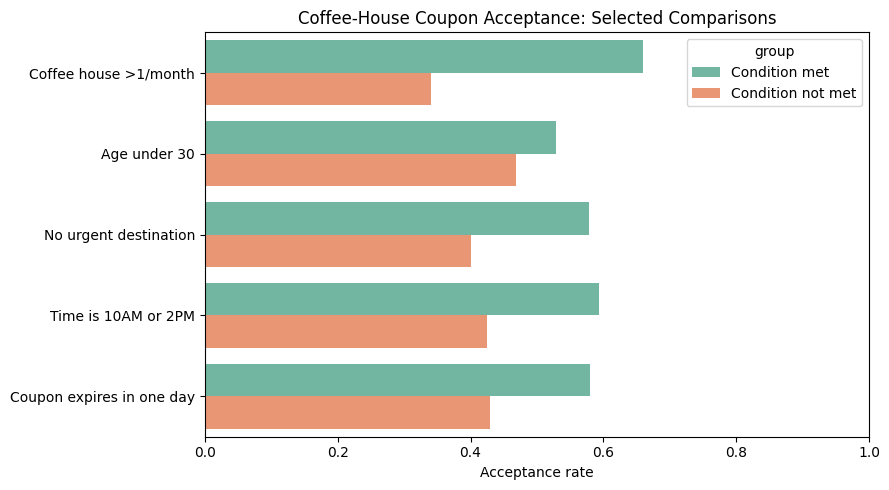

In [89]:
# Compare several interpretable two-group contextual splits.
segments = {
    'Coffee house >1/month': coffee_data['coffee_visits'].gt(1),
    'Age under 30': coffee_data['age_numeric'].lt(30),
    'No urgent destination': coffee_data['destination'].eq('No Urgent Place'),
    'Time is 10AM or 2PM': coffee_data['time'].isin(['10AM', '2PM']),
    'Coupon expires in one day': coffee_data['expiration'].eq('1d')
}

rows = []
for label, mask in segments.items():
    rows.extend([
        {'factor': label, 'group': 'Condition met', 'observations': int(mask.sum()),
         'acceptance_rate': coffee_data.loc[mask, 'Y'].mean()},
        {'factor': label, 'group': 'Condition not met', 'observations': int((~mask).sum()),
         'acceptance_rate': coffee_data.loc[~mask, 'Y'].mean()}
    ])
coffee_segment_summary = pd.DataFrame(rows)
display(coffee_segment_summary.style.format({'acceptance_rate': '{:.1%}'}))

plt.figure(figsize=(9, 5))
sns.barplot(data=coffee_segment_summary, y='factor', x='acceptance_rate',
            hue='group', palette='Set2')
plt.xlim(0, 1)
plt.xlabel('Acceptance rate')
plt.ylabel('')
plt.title('Coffee-House Coupon Acceptance: Selected Comparisons')
plt.tight_layout()
plt.show()


#### Coffee-house findings

- Overall Acceptance: Just under half of drivers (49.6%) accepted coffee house coupons.

- Habit is Key: Regular coffee-goers (2+ visits a month) accepted coupons at 65.9%, compared to just 34.0% for non-frequent visitors.

- Timing & Context: Acceptance was significantly higher when drivers: 
    - Had no urgent destination (57.8% vs. 40.1% for those in a hurry).
    - Received the coupon at 10 AM or 2 PM (59.3% vs. 42.5% at other times).
    - Got a 1-day expiration instead of 2 hours (58.1% vs. 42.9%).

- Age Has Less Impact: Younger drivers (under 30) accepted at a slightly higher rate (52.9%) than drivers 30 and older (46.8%).

- Key Takeaway: Target existing coffee drinkers when they are relaxed and traveling around mid-morning or mid-afternoon, giving them a longer window to redeem. (Note: These are strong patterns in survey data, not guaranteed cause-and-effect).